# Exploratory Data Analysis (EDA) — House Price Prediction
**ML Zoomcamp Project**

This notebook explores the housing dataset, checks data integrity, analyzes the distribution of the target variable (`house_price`), investigates feature correlations and multicollinearity, and evaluates feature importance prior to model training.

## Step 1: Setup, Data Loading & Column Standardization

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.metrics import mean_squared_error, r2_score

# Display settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

# Global constants
RANDOM_STATE = 42
REFERENCE_YEAR = 2026  # Fixed reference year (avoids leakage from using dataset statistics)
TARGET = "house_price"

In [10]:
# Load the dataset (update the filename if needed)
df = pd.read_csv("data/house_price_regression_dataset.csv")

# Standardize column names (lowercase, spaces replaced by underscores)
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

print(f"Dataset shape: {df.shape[0]} rows and {df.shape[1]} columns")
print("Standardized columns:", df.columns.tolist())
df.head(10)

Dataset shape: 1000 rows and 8 columns
Standardized columns: ['square_footage', 'num_bedrooms', 'num_bathrooms', 'year_built', 'lot_size', 'garage_size', 'neighborhood_quality', 'house_price']


,square_footage,num_bedrooms,num_bathrooms,year_built,lot_size,garage_size,neighborhood_quality,house_price
0,1360,2,1,1981,0.600,0,5,262382.852
1,4272,3,3,2016,4.753,1,6,985260.854
2,3592,1,2,2016,3.635,0,9,777977.390
3,966,1,2,1977,2.731,1,8,229698.919
4,4926,2,1,1993,4.699,0,8,1041740.859
5,3944,5,3,1990,2.476,2,8,879796.984
6,3671,1,2,2012,4.912,0,1,814427.861
7,3419,1,1,1972,2.805,1,1,703413.111
8,630,3,3,1997,1.014,1,8,173875.037
9,2185,4,2,1981,3.942,2,5,504176.506


## Step 2: Data Quality Checks (Types, Missing Values, Duplicates & Summary Stats)

In [11]:
print("=== 1. COLUMN TYPES AND MEMORY USAGE ===")
df.info()

print("\n=== 2. MISSING VALUES ===")
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({"Missing": missing, "Percentage (%)": missing_pct})
if missing.sum() > 0:
    print(missing_df[missing_df["Missing"] > 0])
else:
    print("No missing values.")

print("\n=== 3. DUPLICATED ROWS ===")
print(f"Number of exact duplicates: {df.duplicated().sum()}")

print("\n=== 4. UNIQUE VALUES PER COLUMN ===")
for col in df.columns:
    print(f"- {col}: {df[col].nunique()} unique values")

=== 1. COLUMN TYPES AND MEMORY USAGE ===
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   square_footage        1000 non-null   int64  
 1   num_bedrooms          1000 non-null   int64  
 2   num_bathrooms         1000 non-null   int64  
 3   year_built            1000 non-null   int64  
 4   lot_size              1000 non-null   float64
 5   garage_size           1000 non-null   int64  
 6   neighborhood_quality  1000 non-null   int64  
 7   house_price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB

=== 2. MISSING VALUES ===
No missing values.

=== 3. DUPLICATED ROWS ===
Number of exact duplicates: 0

=== 4. UNIQUE VALUES PER COLUMN ===
- square_footage: 894 unique values
- num_bedrooms: 5 unique values
- num_bathrooms: 3 unique values
- year_built: 73 unique values
- lot_size: 1000 unique values


In [12]:
# Extended descriptive statistics (min, max, median, IQR, skewness, kurtosis)
stats_df = df.describe().T
stats_df["IQR"] = stats_df["75%"] - stats_df["25%"]
stats_df["Skewness"] = df.skew()
stats_df["Kurtosis"] = df.kurt()
stats_df

,count,mean,std,min,25%,50%,75%,max,IQR,Skewness,Kurtosis
square_footage,1000.000,2815.422,1255.515,503.000,1749.500,2862.500,3849.500,4999.000,2100.000,-0.066,-1.128
num_bedrooms,1000.000,2.990,1.428,1.000,2.000,3.000,4.000,5.000,2.000,0.026,-1.334
num_bathrooms,1000.000,1.973,0.820,1.000,1.000,2.000,3.000,3.000,2.000,0.050,-1.512
year_built,1000.000,1986.550,20.633,1950.000,1969.000,1986.000,2004.250,2022.000,35.250,-0.021,-1.185
lot_size,1000.000,2.778,1.298,0.506,1.666,2.810,3.923,4.989,2.257,-0.044,-1.201
garage_size,1000.000,1.022,0.815,0.000,0.000,1.000,2.000,2.000,2.000,-0.040,-1.493
neighborhood_quality,1000.000,5.615,2.887,1.000,3.000,6.000,8.000,10.000,5.000,-0.020,-1.206
house_price,1000.000,618861.019,253568.058,111626.853,401648.229,628267.291,827141.278,1108236.836,425493.049,-0.064,-1.091


## Step 3: Target Variable Analysis (`house_price`)

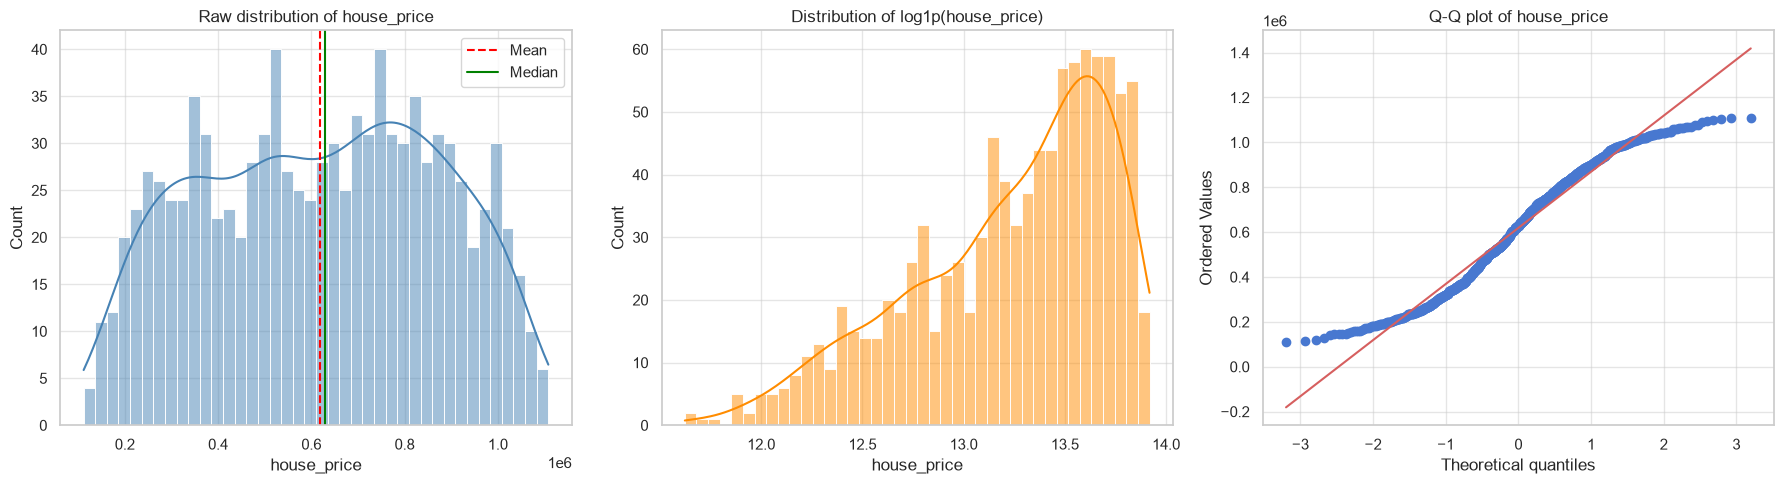

Min price    : $111,626.85
Median price : $628,267.29
Mean price   : $618,861.02
Max price    : $1,108,236.84
Raw skewness : -0.0640 | log1p skewness: -0.8015


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Raw distribution
sns.histplot(df[TARGET], kde=True, bins=40, ax=axes[0], color="steelblue")
axes[0].axvline(df[TARGET].mean(), color="red", linestyle="--", label="Mean")
axes[0].axvline(df[TARGET].median(), color="green", linestyle="-", label="Median")
axes[0].set_title("Raw distribution of house_price")
axes[0].legend()

# 2. Distribution after log1p transformation
sns.histplot(np.log1p(df[TARGET]), kde=True, bins=40, ax=axes[1], color="darkorange")
axes[1].set_title("Distribution of log1p(house_price)")

# 3. Q-Q plot to check normality
stats.probplot(df[TARGET], dist="norm", plot=axes[2])
axes[2].set_title("Q-Q plot of house_price")

plt.tight_layout()
plt.show()

print(f"Min price    : ${df[TARGET].min():,.2f}")
print(f"Median price : ${df[TARGET].median():,.2f}")
print(f"Mean price   : ${df[TARGET].mean():,.2f}")
print(f"Max price    : ${df[TARGET].max():,.2f}")
print(f"Raw skewness : {df[TARGET].skew():.4f} | log1p skewness: {np.log1p(df[TARGET]).skew():.4f}")

* **Value Range:** House prices range from **$111,626.85** to **$1,108,236.84**, with no isolated extreme outliers.
* **Distribution Shape:** The raw distribution is widely spread (roughly uniform with rounded edges between $200k and $1M), which accounts for the slight tail deviations at both ends of the Q-Q plot.
* **Justified Technical Choice:** Since the target variable is already symmetric (`skew = -0.0640`), applying a logarithmic transformation (`log1p`) is unnecessary and would actually introduce artificial skewness.

## Step 4: Univariate Analysis & Outlier Detection

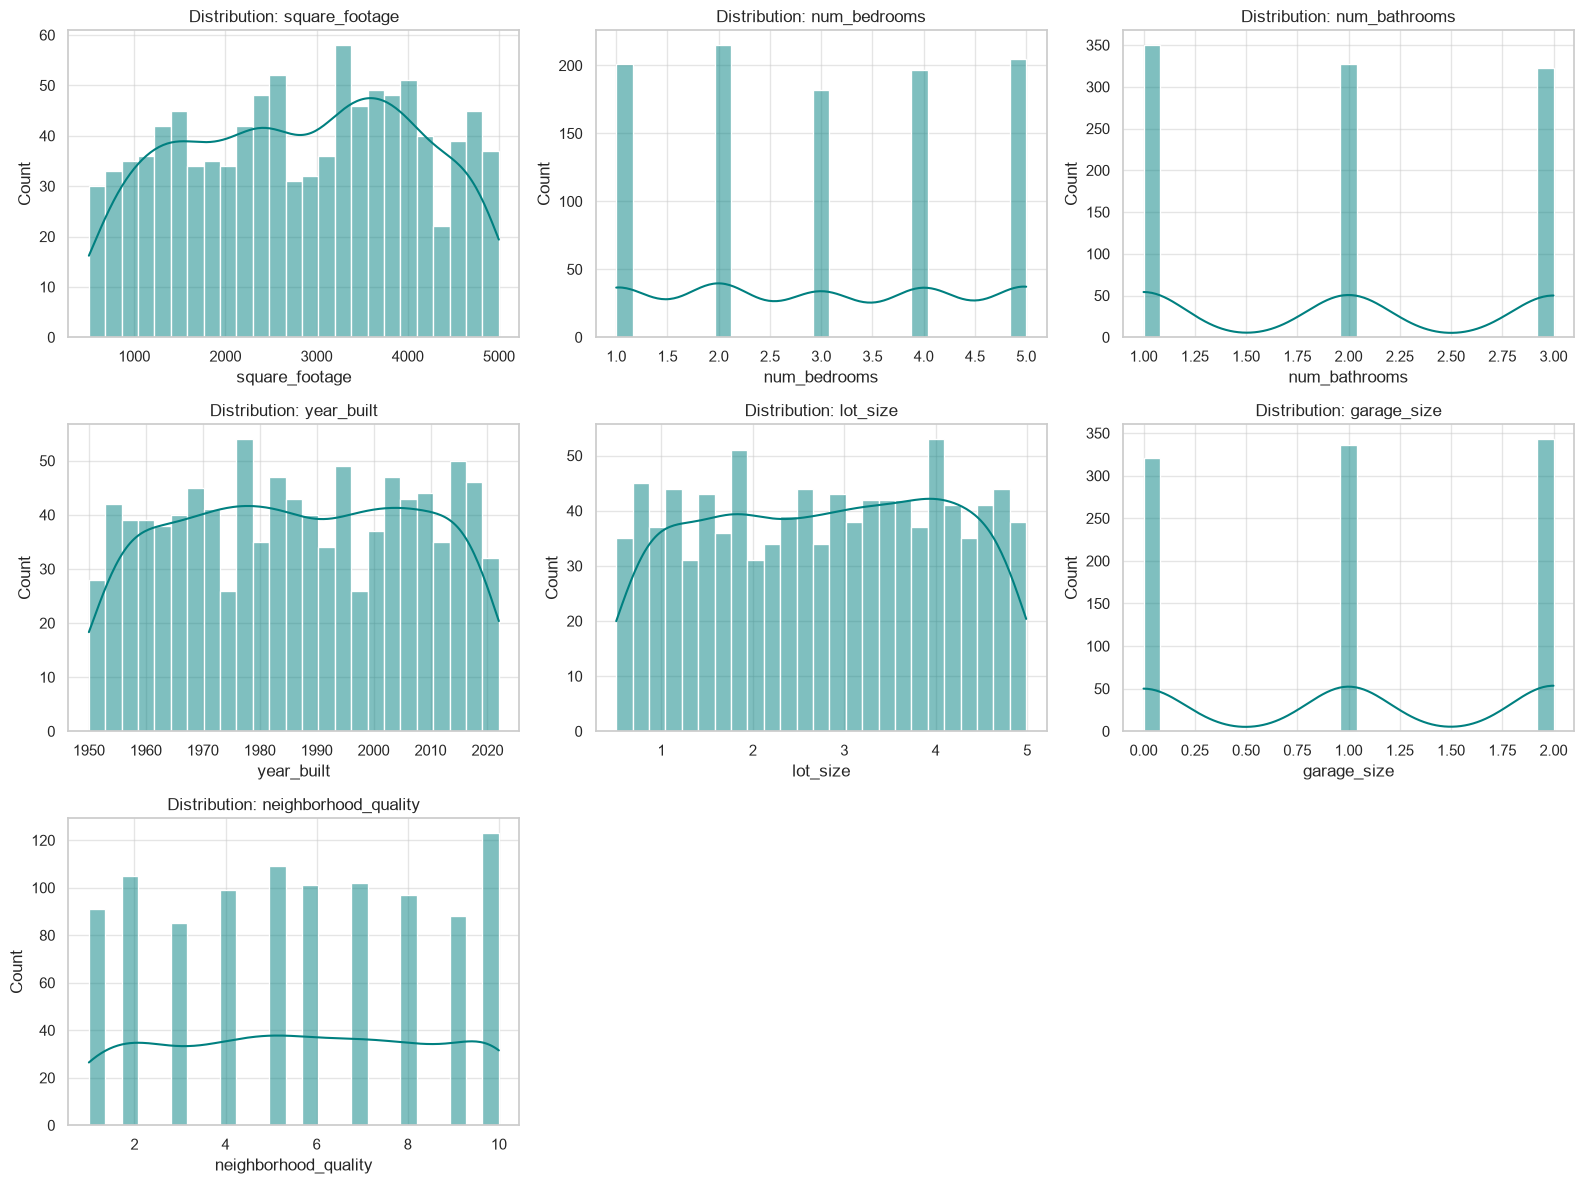

In [14]:
features = [col for col in df.columns if col != TARGET]

# Histograms of all features
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(16, 12))
axes = axes.flatten()

for idx, col in enumerate(features):
    sns.histplot(df[col], kde=True, bins=25, ax=axes[idx], color="teal")
    axes[idx].set_title(f"Distribution: {col}")

# Hide unused subplots
for j in range(len(features), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

=== OUTLIER DETECTION (IQR METHOD) ===
- square_footage        : 0 outliers (bounds: [-1400.50, 6999.50])
- num_bedrooms          : 0 outliers (bounds: [-1.00, 7.00])
- num_bathrooms         : 0 outliers (bounds: [-2.00, 6.00])
- year_built            : 0 outliers (bounds: [1916.12, 2057.12])
- lot_size              : 0 outliers (bounds: [-1.72, 7.31])
- garage_size           : 0 outliers (bounds: [-3.00, 5.00])
- neighborhood_quality  : 0 outliers (bounds: [-4.50, 15.50])
- house_price           : 0 outliers (bounds: [-236591.34, 1465380.85])


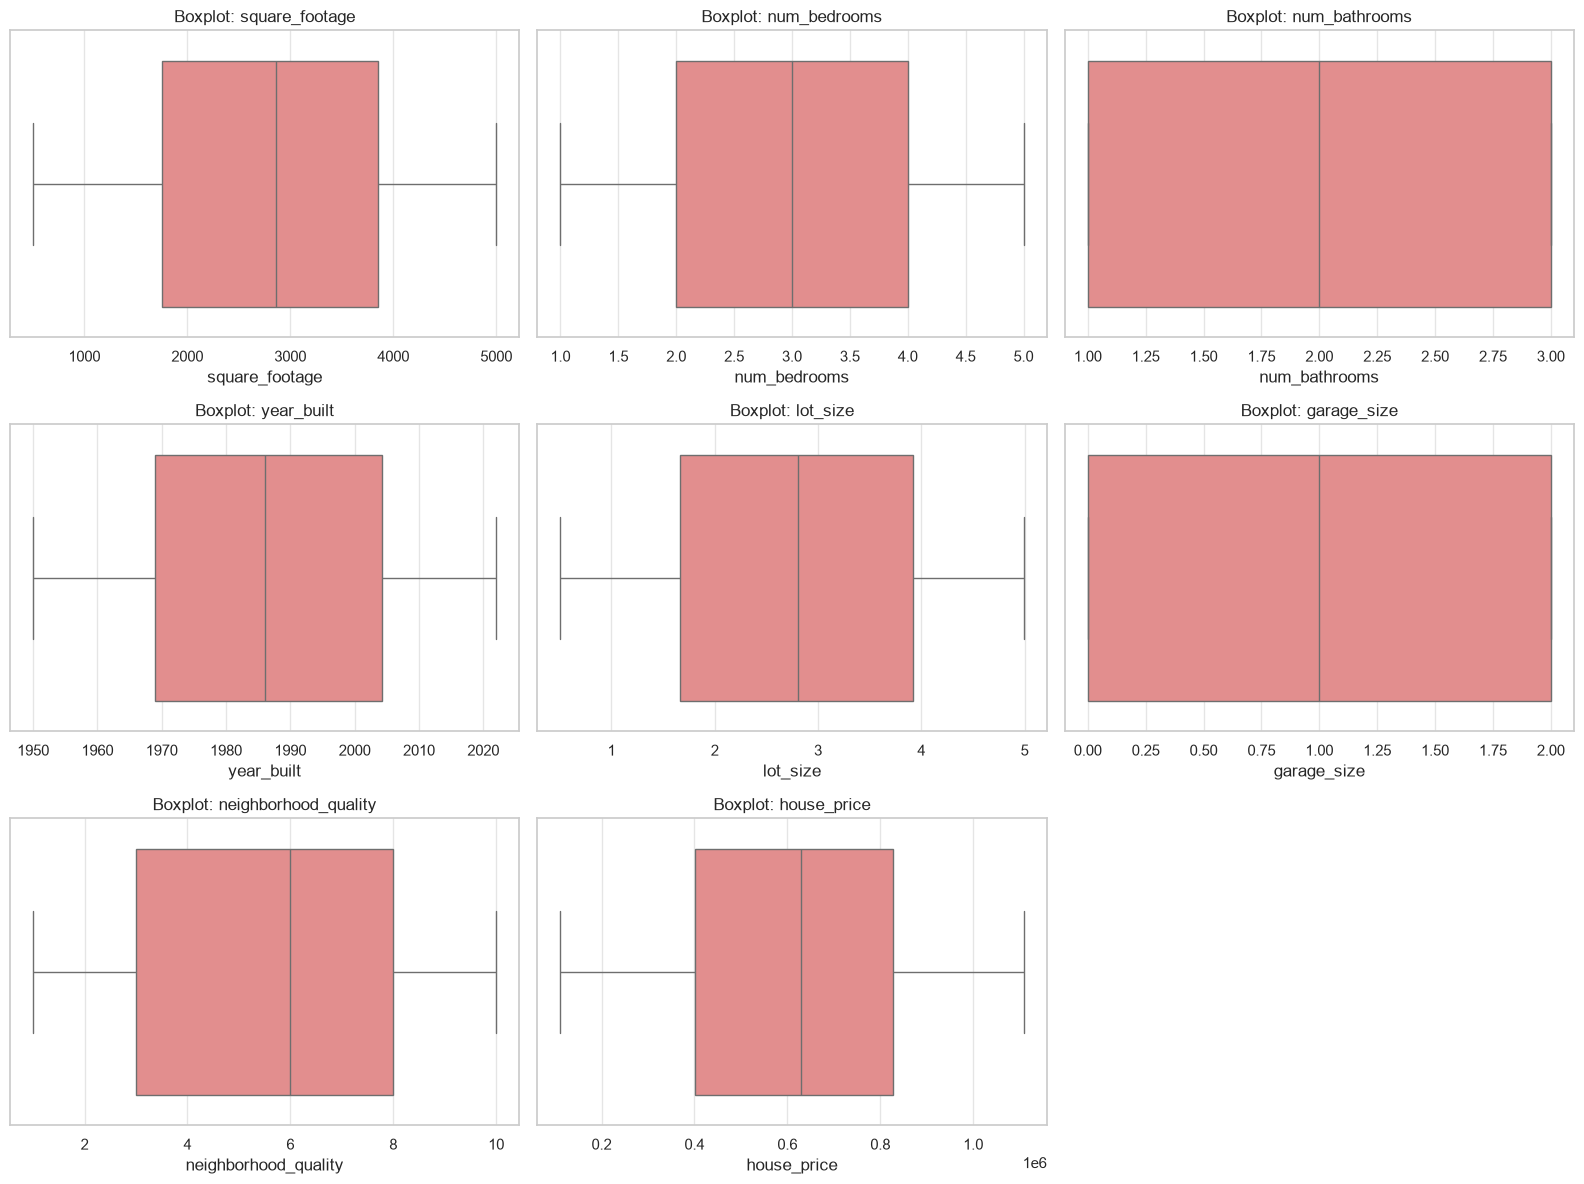

In [15]:
# Outlier detection (IQR method) + boxplots
print("=== OUTLIER DETECTION (IQR METHOD) ===")
for col in df.columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    n_outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    print(f"- {col:22s}: {n_outliers} outliers (bounds: [{lower_bound:.2f}, {upper_bound:.2f}])")

# Boxplots of all columns (7 features + target = 8 plots)
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(16, 12))
axes = axes.flatten()

for idx, col in enumerate(df.columns):
    sns.boxplot(x=df[col], ax=axes[idx], color="lightcoral")
    axes[idx].set_title(f"Boxplot: {col}")

for j in range(len(df.columns), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

## Step 5: Bivariate & Multivariate Analysis (Correlations, Multicollinearity & Interactions)

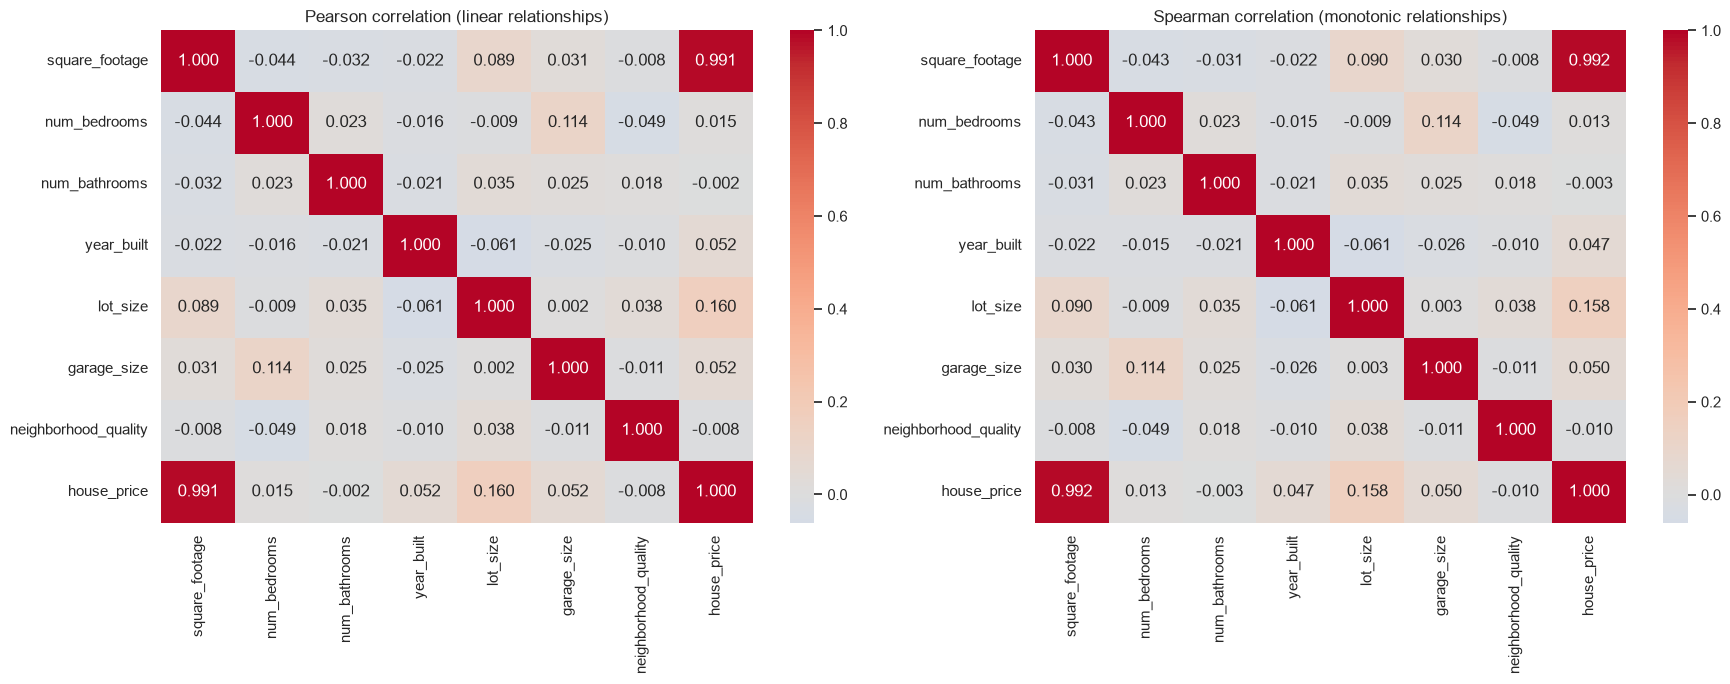

Pearson correlation with house_price:
house_price             1.000
square_footage          0.991
lot_size                0.160
garage_size             0.052
year_built              0.052
num_bedrooms            0.015
num_bathrooms          -0.002
neighborhood_quality   -0.008
Name: house_price, dtype: float64


In [16]:
# Correlation matrices: Pearson (linear) vs Spearman (monotonic)
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(df.corr(method="pearson"), annot=True, fmt=".3f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Pearson correlation (linear relationships)")

sns.heatmap(df.corr(method="spearman"), annot=True, fmt=".3f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Spearman correlation (monotonic relationships)")

plt.tight_layout()
plt.show()

print("Pearson correlation with house_price:")
print(df.corr()[TARGET].sort_values(ascending=False))

In [17]:
# Multicollinearity check (VIF) on the original features
# Rule of thumb: VIF > 5 suggests notable multicollinearity, VIF > 10 is a serious concern.
vif_data = []
for col in features:
    others = [c for c in features if c != col]
    r2 = LinearRegression().fit(df[others], df[col]).score(df[others], df[col])
    vif_data.append({"Feature": col, "VIF": 1 / (1 - r2)})

print("=== VARIANCE INFLATION FACTORS (original features) ===")
print(pd.DataFrame(vif_data).sort_values("VIF", ascending=False).to_string(index=False))

=== VARIANCE INFLATION FACTORS (original features) ===
             Feature   VIF
        num_bedrooms 1.018
         garage_size 1.016
            lot_size 1.014
      square_footage 1.013
          year_built 1.005
neighborhood_quality 1.004
       num_bathrooms 1.004


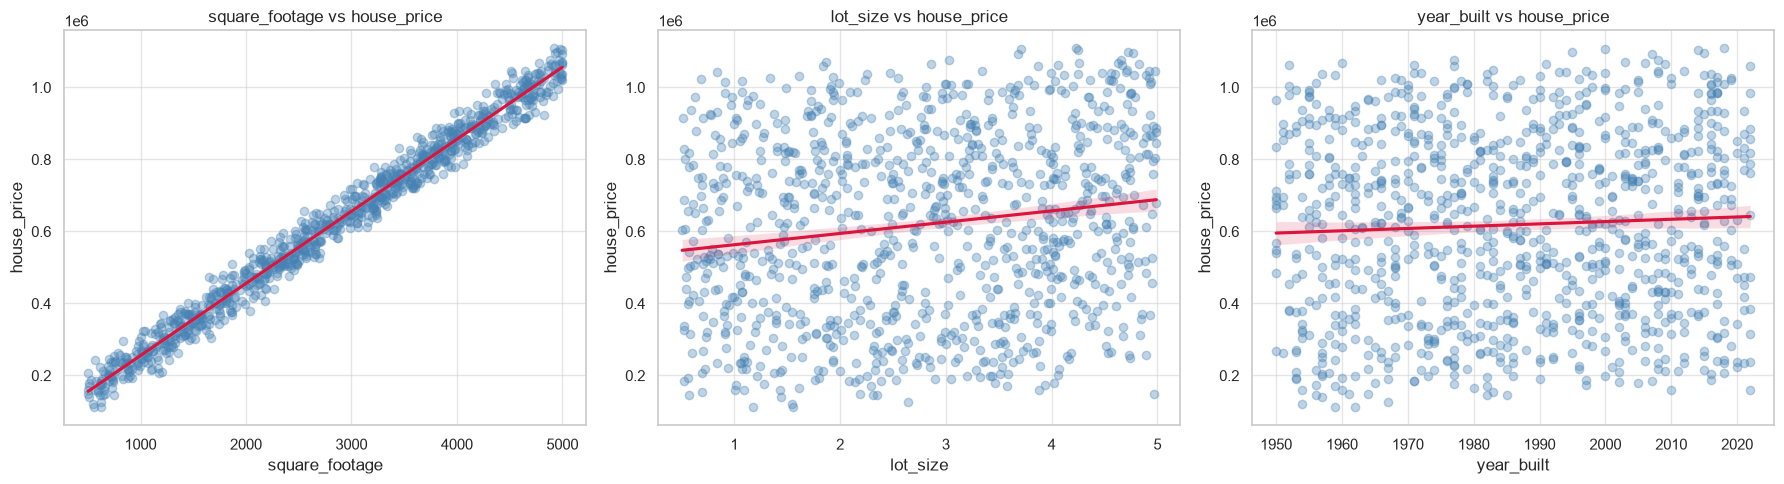

In [18]:
# Linear relationship plots for continuous variables
continuous_cols = ["square_footage", "lot_size", "year_built"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, col in enumerate(continuous_cols):
    sns.regplot(
        data=df, x=col, y=TARGET, ax=axes[idx],
        scatter_kws={"alpha": 0.35, "color": "steelblue"},
        line_kws={"color": "crimson"}
    )
    axes[idx].set_title(f"{col} vs house_price")

plt.tight_layout()
plt.show()

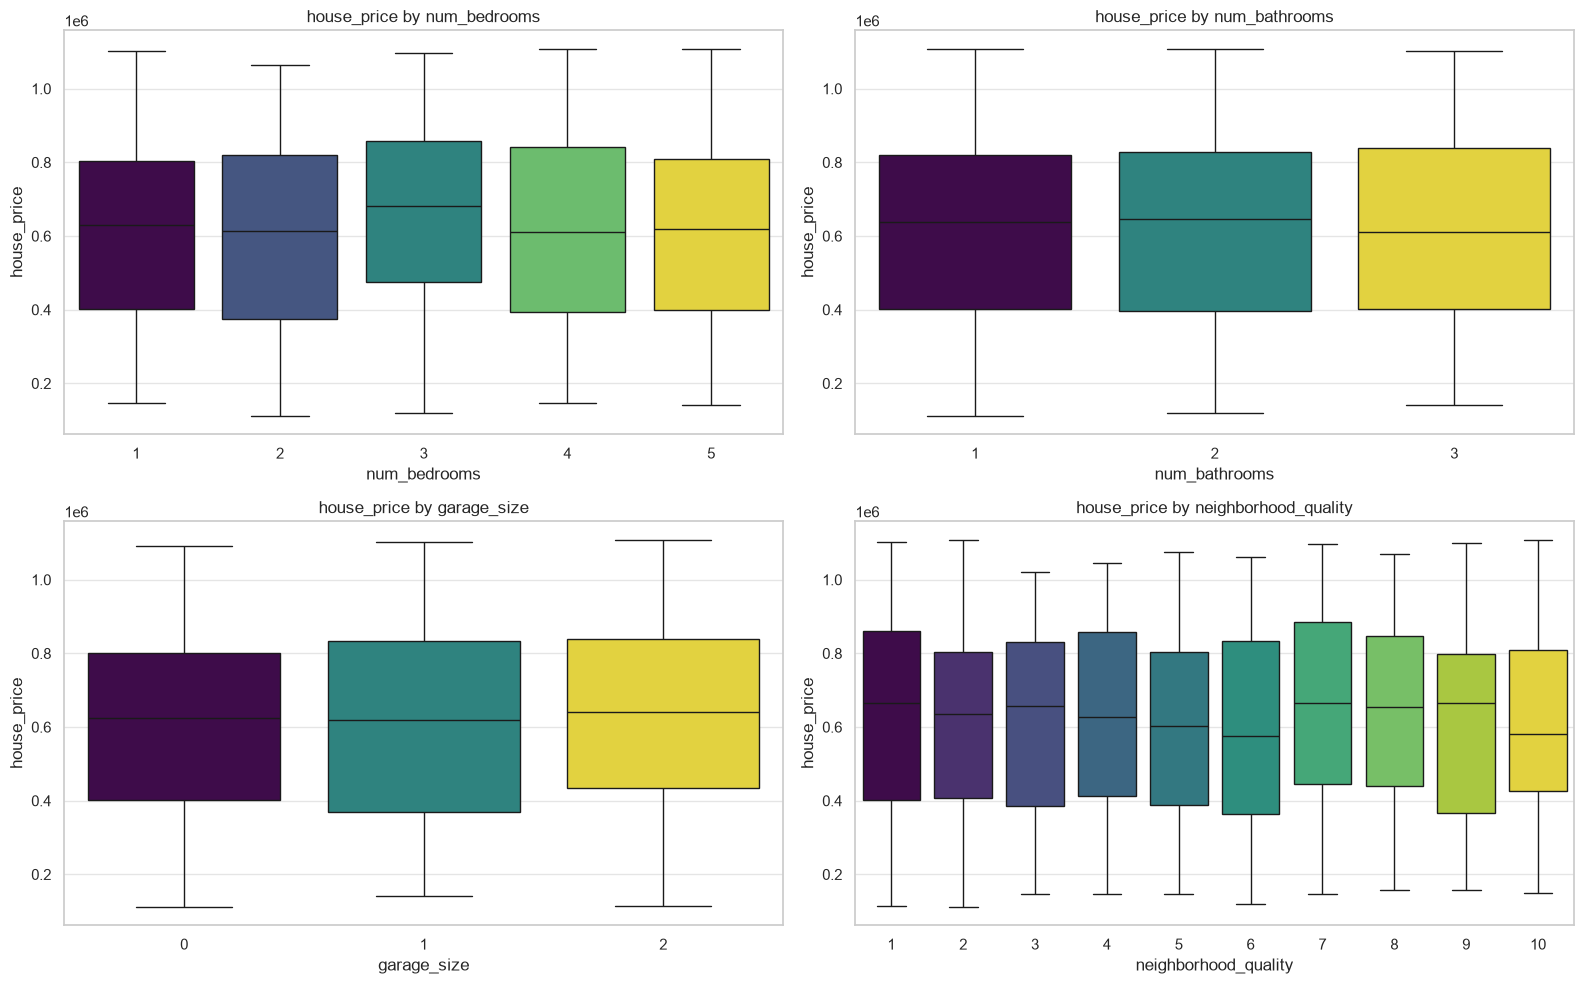

=== MEAN AND MEDIAN PRICE BY NEIGHBORHOOD QUALITY ===
                      count       mean     median        std
neighborhood_quality                                        
1                        91 632968.700 663904.993 268239.371
2                       105 613066.045 635097.396 251391.070
3                        85 625680.913 656223.163 246546.760
4                        99 629867.221 626454.278 260256.215
5                       109 595239.564 602549.278 246143.232
6                       101 593803.860 574912.766 265932.529
7                       102 648856.343 664199.610 264277.321
8                        97 630746.109 654466.945 238596.380
9                        88 617873.065 666351.523 255896.398
10                      123 607767.057 581948.160 245054.332


In [19]:
# Group analysis for discrete variables
discrete_cols = ["num_bedrooms", "num_bathrooms", "garage_size", "neighborhood_quality"]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for idx, col in enumerate(discrete_cols):
    sns.boxplot(
        data=df, x=col, y=TARGET, hue=col,
        palette="viridis", legend=False, ax=axes[idx]
    )
    axes[idx].set_title(f"house_price by {col}")

plt.tight_layout()
plt.show()

# Summary table: mean and median price by neighborhood quality
print("=== MEAN AND MEDIAN PRICE BY NEIGHBORHOOD QUALITY ===")
print(df.groupby("neighborhood_quality")[TARGET].agg(["count", "mean", "median", "std"]))

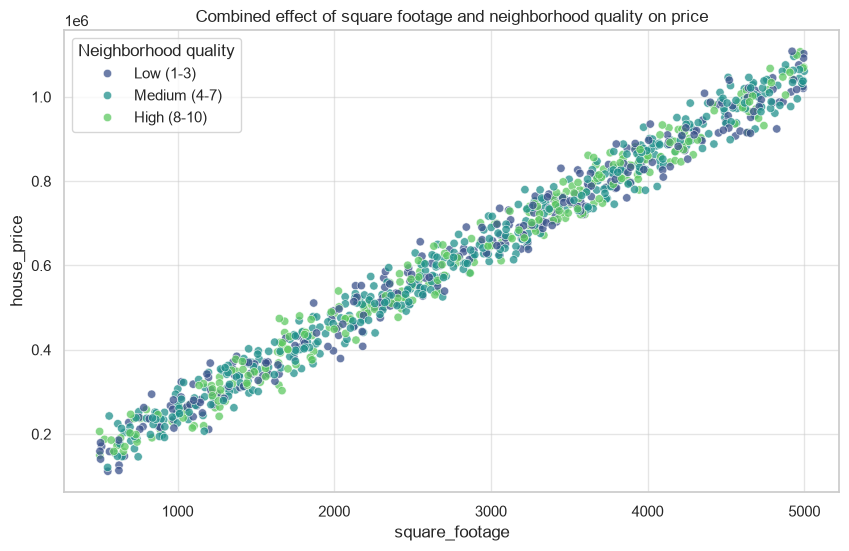

In [20]:
# Multivariate analysis: interaction square_footage x neighborhood_quality -> price
quality_group = pd.cut(
    df["neighborhood_quality"],
    bins=[0, 3, 7, 10],
    labels=["Low (1-3)", "Medium (4-7)", "High (8-10)"]
)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, x="square_footage", y=TARGET,
    hue=quality_group, palette="viridis", alpha=0.75
)
plt.title("Combined effect of square footage and neighborhood quality on price")
plt.legend(title="Neighborhood quality")
plt.show()

## Step 6: Exploratory Feature Engineering

In [21]:
df_fe = df.copy()

# 1. House age, using a fixed reference year (no dataset statistics involved)
df_fe["house_age"] = REFERENCE_YEAR - df_fe["year_built"]

# 2. Total number of rooms and average square footage per room
df_fe["total_rooms"] = df_fe["num_bedrooms"] + df_fe["num_bathrooms"]
df_fe["sqft_per_room"] = df_fe["square_footage"] / df_fe["total_rooms"].replace(0, np.nan)

# 3. Building-to-lot ratio (built density: 1 acre = 43,560 sq ft)
df_fe["building_to_lot_ratio"] = df_fe["square_footage"] / (df_fe["lot_size"].replace(0, np.nan) * 43560)

derived_features = ["house_age", "total_rooms", "sqft_per_room", "building_to_lot_ratio"]

print("=== CORRELATION OF DERIVED FEATURES WITH HOUSE_PRICE ===")
print(df_fe[derived_features + [TARGET]].corr()[TARGET].sort_values(ascending=False))
print("\nNote: house_age is a linear transformation of year_built (correlation = -1 between them).")

=== CORRELATION OF DERIVED FEATURES WITH HOUSE_PRICE ===
house_price              1.000
sqft_per_room            0.652
building_to_lot_ratio    0.398
total_rooms              0.012
house_age               -0.052
Name: house_price, dtype: float64

Note: house_age is a linear transformation of year_built (correlation = -1 between them).


## Step 7: Feature Importance Analysis (Mutual Information, Ridge & Random Forest)

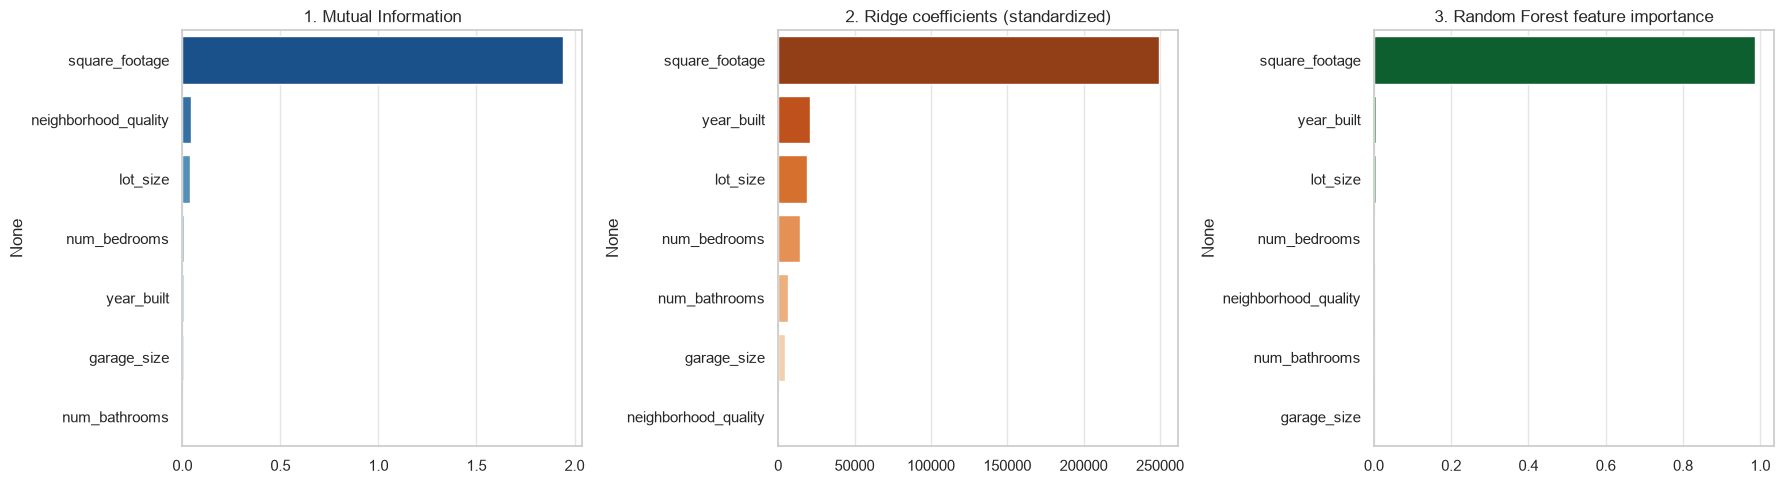

=== FEATURE IMPORTANCE COMPARISON TABLE ===
                      Mutual_Info  Ridge_Abs_Coef  Random_Forest
square_footage              1.943      249471.043          0.986
year_built                  0.008       20628.928          0.005
lot_size                    0.040       19102.481          0.005
num_bedrooms                0.010       14495.372          0.002
neighborhood_quality        0.043         330.862          0.001
num_bathrooms               0.000        6675.307          0.001
garage_size                 0.007        4232.293          0.000


In [22]:
# Computed on the 7 ORIGINAL features only to avoid splitting importance between collinear variables
X = df[features]
y = df[TARGET]

# Train/validation split BEFORE any importance computation
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

# Method 1: Mutual information (captures linear and non-linear relationships)
discrete_features = [
    "num_bedrooms", "num_bathrooms", "garage_size", "neighborhood_quality"
]
discrete_mask = [col in discrete_features for col in X_train.columns]
mi_scores = mutual_info_regression(
    X_train, y_train, discrete_features=discrete_mask, random_state=RANDOM_STATE
)
mi_series = pd.Series(mi_scores, index=X_train.columns).sort_values(ascending=False)

# Method 2: Standardized Ridge coefficients (linear importance)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)
ridge_series = pd.Series(np.abs(ridge.coef_), index=X_train.columns).sort_values(ascending=False)

# Method 3: Tree-based importance (Random Forest)
rf = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
rf_series = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)

# Comparative visualization of the 3 approaches
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(x=mi_series.values, y=mi_series.index, hue=mi_series.index,
            palette="Blues_r", legend=False, ax=axes[0])
axes[0].set_title("1. Mutual Information")

sns.barplot(x=ridge_series.values, y=ridge_series.index, hue=ridge_series.index,
            palette="Oranges_r", legend=False, ax=axes[1])
axes[1].set_title("2. Ridge coefficients (standardized)")

sns.barplot(x=rf_series.values, y=rf_series.index, hue=rf_series.index,
            palette="Greens_r", legend=False, ax=axes[2])
axes[2].set_title("3. Random Forest feature importance")

plt.tight_layout()
plt.show()

# Full comparison table
importance_summary = pd.DataFrame({
    "Mutual_Info": mi_series,
    "Ridge_Abs_Coef": ridge_series,
    "Random_Forest": rf_series
}).sort_values(by="Random_Forest", ascending=False)

print("=== FEATURE IMPORTANCE COMPARISON TABLE ===")
print(importance_summary)

In [23]:
# Test whether derived features improve validation performance
def evaluate_rf(feature_list):
    """Train a Random Forest on the given features and return validation RMSE and R2."""
    X_tr, X_va, y_tr, y_va = train_test_split(
        df_fe[feature_list].fillna(0), df_fe[TARGET],
        test_size=0.2, random_state=RANDOM_STATE
    )
    model = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
    model.fit(X_tr, y_tr)
    preds = model.predict(X_va)
    rmse = np.sqrt(mean_squared_error(y_va, preds))
    return rmse, r2_score(y_va, preds)

rmse_base, r2_base = evaluate_rf(features)
rmse_fe, r2_fe = evaluate_rf(features + derived_features)

comparison = pd.DataFrame({
    "Feature set": ["Original features", "Original + derived features"],
    "Validation RMSE": [rmse_base, rmse_fe],
    "Validation R2": [r2_base, r2_fe],
})
print("=== IMPACT OF DERIVED FEATURES (Random Forest) ===")
print(comparison.to_string(index=False))

=== IMPACT OF DERIVED FEATURES (Random Forest) ===
                Feature set  Validation RMSE  Validation R2
          Original features        19825.267          0.994
Original + derived features        20000.944          0.994


## Step 8: Key Findings from Exploratory Data Analysis (EDA)

* **Data Integrity:** The dataset contains **1,000** records and 7 numeric features plus the target (`house_price`), with **0 missing values** and **0 duplicate rows**.
* **Target Variable (`house_price`):** Ranges from **$111,626.85** to **$1,108,236.84** (median: **$628,267.29**, mean: **$618,861.02**), with a raw skewness of **-0.0640**. Since the distribution is already symmetric (whereas `log1p` introduces a skewness of **-0.8015**), no target transformation is needed.
* **Outlier Analysis:** The IQR method flagged **0 outliers** across all 8 columns, confirming clean and well-bounded distributions.
* **Correlations:** The strongest Pearson correlations with `house_price` are **`square_footage` (`r = 0.991`)**, **`lot_size` (`r = 0.160`)**, **`garage_size` (`r = 0.052`)**, and **`year_built` (`r = 0.052`)**, while `neighborhood_quality` (`r = -0.008`) shows virtually no linear impact.
* **Multicollinearity:** All Variance Inflation Factor (VIF) values are extremely low (**1.004 to 1.018**, well below the threshold of 5), indicating no multicollinearity among the original features.
* **Primary Price Drivers:** Mutual Information (`1.943`), standardized Ridge coefficients (`249,471`), and Random Forest importance (`0.986`) all agree that **`square_footage`** is by far the dominant predictor, followed by secondary contributions from **`year_built`**, **`lot_size`**, and **`num_bedrooms`**.
* **Derived Features:** Adding engineered features (`house_age`, `total_rooms`, `sqft_per_room`, `building_to_lot_ratio`) slightly degraded Random Forest validation RMSE (**$20,000.94** vs **$19,825.27** on original features), so they are **dropped** in favor of the cleaner 7 original features.
* **Modeling Strategy:** Given the strong linear relationship between features and price, the models to be trained and compared next are **Linear Regression, Ridge, Lasso, Decision Tree, Random Forest, and XGBoost**, using **RMSE** as the primary evaluation metric.

## Step 9: Data Splitting (`Train` / `Validation` / `Test`) & Baseline Model

In [25]:
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

# 60% Train, 20% Validation, 20% Test split (using the 7 original features)
X = df[features]
y = df[TARGET].values

X_full_train, X_test, y_full_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_full_train, y_full_train, test_size=0.25, random_state=RANDOM_STATE  # 0.25 x 0.8 = 0.20
)

print(f"Train set      : {X_train.shape[0]} rows")
print(f"Validation set : {X_val.shape[0]} rows")
print(f"Test set       : {X_test.shape[0]} rows")

# Naive baseline: predicting the mean house price from the training set
baseline_pred = np.full_like(y_val, y_train.mean(), dtype=float)
baseline_rmse = rmse(y_val, baseline_pred)
print(f"\nBaseline (mean prediction) Validation RMSE: ${baseline_rmse:,.2f}")

Train set      : 600 rows
Validation set : 200 rows
Test set       : 200 rows

Baseline (mean prediction) Validation RMSE: $263,678.12


## Step 10: Model Comparison Across Multiple Families
We compare 6 regression algorithms across linear models and tree-based ensembles using default parameters on the validation set, as well as 5-fold cross-validation on `full_train`.

In [27]:
# Standardize features inside pipelines for linear models to prevent data leakage
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge (alpha=1.0)": make_pipeline(StandardScaler(), Ridge(alpha=1.0, random_state=RANDOM_STATE)),
    "Lasso (alpha=1.0)": make_pipeline(StandardScaler(), Lasso(alpha=1.0, random_state=RANDOM_STATE)),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []

for name, model in models.items():
    # Fit on Train, evaluate on Validation
    model.fit(X_train, y_train)
    val_preds = model.predict(X_val)

    val_rmse = np.sqrt(mean_squared_error(y_val, val_preds))
    val_mae = mean_absolute_error(y_val, val_preds)
    val_r2 = r2_score(y_val, val_preds)

    # 5-fold cross-validation on full_train
    cv_scores = -cross_val_score(
        model, X_full_train, y_full_train,
        cv=kfold, scoring="neg_root_mean_squared_error", n_jobs=-1
    )

    results.append({
        "Model": name,
        "Val RMSE ($)": val_rmse,
        "Val MAE ($)": val_mae,
        "Val R2": val_r2,
        "CV Mean RMSE ($)": cv_scores.mean(),
        "CV Std RMSE ($)": cv_scores.std(),
    })

results_df = pd.DataFrame(results).sort_values(by="Val RMSE ($)")
print("=== MODEL COMPARISON SUMMARY ===")
results_df

=== MODEL COMPARISON SUMMARY ===


,Model,Val RMSE ($),Val MAE ($),Val R2,CV Mean RMSE ($),CV Std RMSE ($)
1,Ridge (alpha=1.0),9295.676,7227.142,0.999,9765.618,727.765
2,Lasso (alpha=1.0),9343.419,7276.996,0.999,9757.421,723.572
0,Linear Regression,9343.651,7277.136,0.999,9757.503,723.660
5,Gradient Boosting,15968.697,12073.387,0.996,16027.761,893.117
4,Random Forest,21636.915,16889.315,0.993,22203.904,1088.898
3,Decision Tree,32781.710,26153.432,0.984,32821.377,355.834


## Step 11: Hyperparameter Tuning
We tune the top linear models (**Ridge** and **Lasso**) and the best tree-based ensemble (**Gradient Boosting** / **Random Forest**) using `GridSearchCV` with 5-fold cross-validation.

In [28]:
# 1. Hyperparameter tuning for Ridge Regression
ridge_pipe = make_pipeline(StandardScaler(), Ridge(random_state=RANDOM_STATE))
ridge_params = {
    "ridge__alpha": [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0]
}
ridge_grid = GridSearchCV(
    ridge_pipe, ridge_params, cv=kfold,
    scoring="neg_root_mean_squared_error", n_jobs=-1
)
ridge_grid.fit(X_full_train, y_full_train)

# 2. Hyperparameter tuning for Lasso Regression
lasso_pipe = make_pipeline(StandardScaler(), Lasso(max_iter=10000, random_state=RANDOM_STATE))
lasso_params = {
    "lasso__alpha": [0.01, 0.1, 1.0, 10.0, 50.0, 100.0, 500.0]
}
lasso_grid = GridSearchCV(
    lasso_pipe, lasso_params, cv=kfold,
    scoring="neg_root_mean_squared_error", n_jobs=-1
)
lasso_grid.fit(X_full_train, y_full_train)

# 3. Hyperparameter tuning for Gradient Boosting
gbr_params = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4],
}
gbr_grid = GridSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE), gbr_params,
    cv=kfold, scoring="neg_root_mean_squared_error", n_jobs=-1
)
gbr_grid.fit(X_full_train, y_full_train)

print(f"Best Ridge CV RMSE            : ${-ridge_grid.best_score_:,.2f} | Params: {ridge_grid.best_params_}")
print(f"Best Lasso CV RMSE            : ${-lasso_grid.best_score_:,.2f} | Params: {lasso_grid.best_params_}")
print(f"Best Gradient Boosting CV RMSE: ${-gbr_grid.best_score_:,.2f} | Params: {gbr_grid.best_params_}")

Best Ridge CV RMSE            : $9,757.50 | Params: {'ridge__alpha': 0.001}
Best Lasso CV RMSE            : $9,752.39 | Params: {'lasso__alpha': 100.0}
Best Gradient Boosting CV RMSE: $14,147.90 | Params: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 300}


## Step 12: Final Model Selection, Test Evaluation & Residual Analysis

Selected Final Model : Tuned Lasso
Best Parameters      : {'lasso__alpha': 100.0}
--------------------------------------------------
Test RMSE            : $10,082.26
Test MAE             : $8,190.77
Test R2              : 0.99842


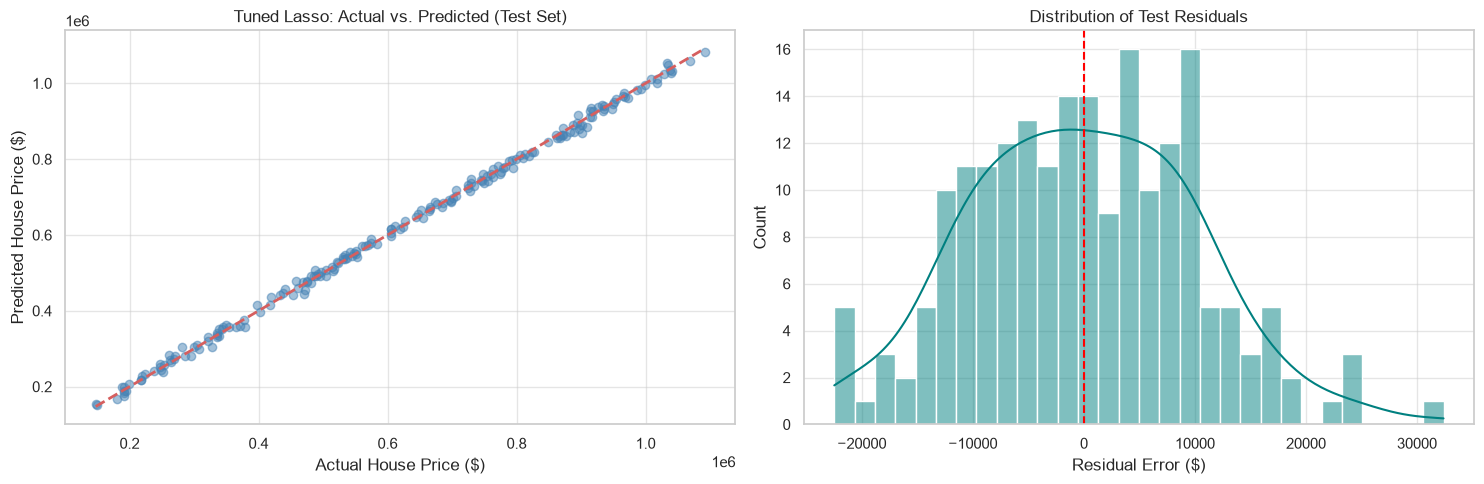

In [29]:
# Select the overall best tuned estimator automatically
candidates = {
    "Tuned Ridge": ridge_grid,
    "Tuned Lasso": lasso_grid,
    "Tuned Gradient Boosting": gbr_grid,
}

best_name = max(candidates, key=lambda k: candidates[k].best_score_)
best_model = candidates[best_name].best_estimator_

# Final evaluation on the held-out Test set (200 unseen houses)
test_preds = best_model.predict(X_test)
test_rmse = np.sqrt(mean_squared_error(y_test, test_preds))
test_mae = mean_absolute_error(y_test, test_preds)
test_r2 = r2_score(y_test, test_preds)

print(f"Selected Final Model : {best_name}")
print(f"Best Parameters      : {candidates[best_name].best_params_}")
print("-" * 50)
print(f"Test RMSE            : ${test_rmse:,.2f}")
print(f"Test MAE             : ${test_mae:,.2f}")
print(f"Test R2              : {test_r2:.5f}")

# Residual diagnostics (Actual vs Predicted & Residuals distribution)
residuals = y_test - test_preds
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(y_test, test_preds, alpha=0.5, color="steelblue")
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2)
axes[0].set_xlabel("Actual House Price ($)")
axes[0].set_ylabel("Predicted House Price ($)")
axes[0].set_title(f"{best_name}: Actual vs. Predicted (Test Set)")

sns.histplot(residuals, kde=True, bins=30, ax=axes[1], color="teal")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("Residual Error ($)")
axes[1].set_title("Distribution of Test Residuals")

plt.tight_layout()
plt.show()

## Step 13: Modeling Conclusions & Final Model Selection

* **Linear vs. Tree-Based Models:** Linear models dramatically outperformed tree-based ensembles across both validation and 5-fold cross-validation (`CV Mean RMSE` of **~$9,752–$9,766** for Lasso/Ridge/Linear Regression vs. **$14,147.90** for tuned Gradient Boosting, **$22,203.90** for Random Forest, and **$32,821.38** for Decision Tree)[cite: 2]. This confirms the strong underlying linear structure identified during EDA.
* **Hyperparameter Tuning:** 5-fold `GridSearchCV` selected **Lasso Regression with `alpha = 100.0`** as the top-performing estimator (`CV RMSE = $9,752.39`), benefiting from L1 regularization to suppress minor noise features.
* **Held-Out Test Set Performance:** Evaluated once on the unseen 20% test split (`200` samples), the final **Tuned Lasso** pipeline achieved:
  * **Test RMSE:** **$10,082.26** (~1.6% of the median house price)
  * **Test MAE:** **$8,190.77**
  * **Test $R^2$:** **0.99842**
* **Next Step (Deployment):** Export this `StandardScaler + Lasso(alpha=100.0)` pipeline into a reproducible training script (`train.py`) and serve it via a containerized web API (`predict.py` + `Dockerfile`).